# 2.2. GIẢI THUẬT 2: SUPPORT VECTOR MACHINE (SVM)

## 2.2.1. Ôn tập lý thuyết

Nguồn câu hỏi: **Lab - Thuat toan phan lop.pdf**, mục 2.2.1, trang 7. Trình bày đủ 7 câu hỏi, hình minh họa và mã mẫu. Chọn kernel **SGU HocMay (Anaconda ổn định)** rồi chạy từ trên xuống.

In [1]:
from pathlib import Path
from time import perf_counter
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn import svm, datasets
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.exceptions import ConvergenceWarning

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams['figure.dpi'] = 120
RANDOM_STATE = 101
# Bao loi neu bo giai chua hoi tu, tranh su dung ket qua huan luyen dang do.
warnings.filterwarnings('error', category=ConvergenceWarning)

### Câu 1

**Câu hỏi:** Giải thuật Support Vector Machine hoạt động như thế nào? Hãy giải thích khái niệm về ranh giới phân tách (hyperplane) và lề (margin).

**Trả lời:**

**SVM** tìm ranh giới phân tách các lớp và ưu tiên ranh giới có lề rộng. Với SVM tuyến tính nhị phân, siêu phẳng có dạng **wᵀx + b = 0**. Trong 2 chiều là một đường thẳng; trong 3 chiều là một mặt phẳng. Dấu của hàm quyết định cho biết phía của ranh giới và được ánh xạ sang nhãn lớp.

**Margin** là khoảng đệm giữa hai mặt **wᵀx+b=+1** và **wᵀx+b=-1** theo cách chuẩn hóa của SVM; bề rộng bằng **2/||w||**. Tối đa hóa lề đồng thời kiểm soát vi phạm giúp mô hình tổng quát hóa. SVM kernel có thể tạo ranh giới phi tuyến trong không gian dữ liệu ban đầu. Hình bên dưới chỉ minh họa hai lớp và hai đặc trưng.

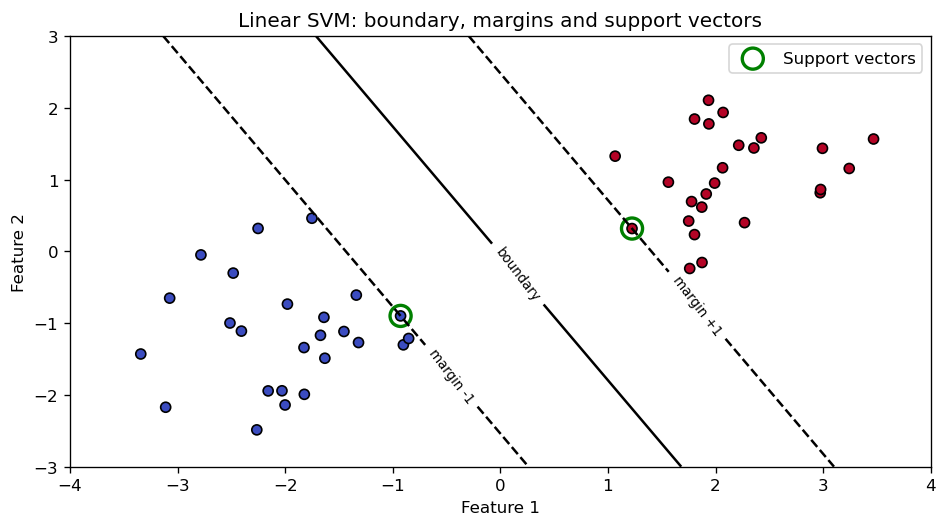

In [2]:
X_demo, y_demo = datasets.make_blobs(n_samples=50, centers=[[-2,-1],[2,1]],
                                    cluster_std=0.65, random_state=7)
demo = svm.SVC(kernel='linear', C=1).fit(X_demo, y_demo)
xx, yy = np.meshgrid(np.linspace(-4,4,200), np.linspace(-3,3,200))
zz = demo.decision_function(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(8,4.5))
ax.scatter(X_demo[:,0],X_demo[:,1],c=y_demo,cmap='coolwarm',edgecolors='k')
lines=ax.contour(xx,yy,zz,levels=[-1,0,1],colors='black',linestyles=['--','-','--'])
ax.clabel(lines,fmt={-1:'margin -1',0:'boundary',1:'margin +1'},fontsize=8)
ax.scatter(demo.support_vectors_[:,0],demo.support_vectors_[:,1],s=160,
           facecolors='none',edgecolors='green',linewidths=2,label='Support vectors')
ax.set(xlabel='Feature 1',ylabel='Feature 2',title='Linear SVM: boundary, margins and support vectors')
ax.legend()
plt.tight_layout()
plt.show()

### Câu 2

**Câu hỏi:** Các vector hỗ trợ (support vectors) có vai trò gì trong SVM? Tại sao chúng quan trọng?

**Trả lời:**

Vector hỗ trợ là các mẫu có hệ số đóng góp khác 0 trong nghiệm SVM kernel. Trong bài toán lề cứng, chúng nằm trên các mặt lề; với lề mềm, có thể nằm trên lề, trong lề hoặc bị phân loại sai. Chúng góp phần xác định vị trí và hướng ranh giới. Vì vậy, thay đổi các mẫu này có thể làm ranh giới thay đổi.

Trong Scikit-learn, SVC có **support_**, **support_vectors_**, **n_support_** để xem chỉ số, tọa độ và số mẫu hỗ trợ. Nếu đã StandardScaler, support_vectors_ ở không gian đã chuẩn hóa. LinearSVC dùng bộ giải khác và không cung cấp các thuộc tính vector hỗ trợ này.

### Câu 3

**Câu hỏi:** Sự khác biệt giữa SVM với lề cứng (hard margin) và lề mềm (soft margin) là gì? Khi nào nên sử dụng lề mềm?

**Trả lời:**

| Nội dung | Lề cứng | Lề mềm |
|---|---|---|
| Điều kiện | Các mẫu phải ở đúng phía và ngoài/đúng trên lề | Cho phép vi phạm lề qua biến ξᵢ ≥ 0 |
| Dữ liệu phù hợp | Phân tách tuyến tính hoàn toàn và ít nhiễu | Có nhiễu, chồng lấn hoặc ngoại lệ |
| Đánh đổi | Không cho phép vi phạm | Cân bằng lề rộng với mức phạt vi phạm |

Lề mềm tối ưu **1/2 ||w||² + C Σξᵢ**, với **yᵢ(wᵀxᵢ+b) ≥ 1-ξᵢ** khi nhãn được biểu diễn -1/+1. Dữ liệu thực tế thường cần lề mềm. C lớn hữu hạn không bảo đảm tự động trở thành lề cứng khi dữ liệu không phân tách được.

### Câu 4

**Câu hỏi:** Hàm nhân (kernel) trong SVM là gì? Hãy giải thích các loại kernel phổ biến (linear, polynomial, RBF) và khi nào nên sử dụng chúng.

**Trả lời:**

Kernel tính mức tương đồng tương ứng với tích vô hướng trong một không gian đặc trưng, giúp học ranh giới phi tuyến mà không cần tạo tường minh tất cả đặc trưng mở rộng.

| Kernel | Biểu thức | Khi cân nhắc |
|---|---|---|
| Linear | K(x,z)=xᵀz | Quan hệ gần tuyến tính, nhiều đặc trưng hoặc cần mô hình đơn giản |
| Polynomial | K(x,z)=(γxᵀz+r)^d | Cần tương tác dạng đa thức; phải chọn degree, gamma, coef0 phù hợp |
| RBF | K(x,z)=exp(-γ||x-z||²) | Ranh giới phi tuyến; lựa chọn phổ biến khi chưa biết dạng quan hệ |

Gamma lớn làm ảnh hưởng của một mẫu cục bộ hơn, ranh giới có thể phức tạp; gamma nhỏ cho ảnh hưởng rộng hơn. Chọn C/gamma/kernel bằng validation hoặc CV và chuẩn hóa trong Pipeline. Không có kernel tốt nhất cho mọi dữ liệu.

### Câu 5

**Câu hỏi:** Tham số C trong SVM có ý nghĩa gì? Nó ảnh hưởng như thế nào đến hiệu suất của mô hình?

**Trả lời:**

C > 0 điều khiển mức phạt vi phạm lề trong hàm mục tiêu. **C lớn** phạt mạnh, tương ứng regularization yếu hơn, cố giảm vi phạm trên train và có thể quá khớp. **C nhỏ** tăng regularization tương đối, chấp nhận nhiều vi phạm hơn và có thể thiếu khớp nếu quá nhỏ.

Ảnh hưởng cụ thể còn phụ thuộc dữ liệu, scaling và kernel; C lớn không bảo đảm test tốt hơn. Thường khảo sát theo thang log, như 0,01; 0,1; 1; 10. C là siêu tham số đặt trước khi fit, khác với hệ số w mà mô hình học.

### Câu 6

**Câu hỏi:** Viết đoạn code mẫu bằng Python (sử dụng Scikit-learn) để xây dựng một mô hình SVM cho bài toán phân loại không? Hãy mô tả các bước thực hiện.

**Trả lời:**

Các bước: nạp dữ liệu Iris, tách X/y, chia train/test, tạo Pipeline(StandardScaler, SVC), fit trên train rồi predict và đánh giá trên test. Iris là hoa **diên vĩ**. Mã bên dưới là ví dụ độc lập, dùng bộ dữ liệu nhỏ có sẵn, không cần tải mạng.

In [3]:
iris_demo=datasets.load_iris()
X_train, X_test, y_train, y_test=train_test_split(
    iris_demo.data,iris_demo.target,test_size=0.2,stratify=iris_demo.target,random_state=42)
clf=Pipeline([('scale',StandardScaler()),('svc',svm.SVC(kernel='rbf',C=1,gamma='scale'))])
clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)
print('Test accuracy:',accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred,target_names=iris_demo.target_names,zero_division=0))

Test accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



### Câu 7

**Câu hỏi:** Hàm nào trong Scikit-learn để chuẩn hóa dữ liệu (scaling) trước khi áp dụng SVM? Tại sao bước này quan trọng?

**Trả lời:**

**StandardScaler** biến đổi mỗi cột bằng (x-mean_train)/std_train. **MinMaxScaler** đưa cột về khoảng chỉ định, thường [0,1], theo min/max của train. Khác đơn vị hoặc thang đo có thể chi phối khoảng cách RBF và mức regularization của SVM tuyến tính.

Chỉ fit scaler trên train, rồi transform validation/test bằng cùng thống kê. Trong CV, dùng Pipeline để scaler được fit lại trong từng fold. Với ma trận sparse one-hot, không trừ trung bình bằng StandardScaler mặc định vì sẽ làm mất tính thưa; thường giữ one-hot 0/1 hoặc dùng with_mean=False khi cần. Scaling không phải mã hóa biến phân loại và không áp lên nhãn y.

In [4]:
scaler=clf.named_steps['scale']
X_train_scaled=scaler.transform(X_train)
X_test_scaled=scaler.transform(X_test)
display(pd.DataFrame({'feature':iris_demo.feature_names,
    'train_mean_after_scale':X_train_scaled.mean(axis=0),
    'train_std_after_scale':X_train_scaled.std(axis=0)}).round(6))
print('Test duoc transform bang thong ke train; khong fit lai tren test.')

,feature,train_mean_after_scale,train_std_after_scale
0,sepal length (cm),-0.0,1.0
1,sepal width (cm),-0.0,1.0
2,petal length (cm),0.0,1.0
3,petal width (cm),0.0,1.0


Test duoc transform bang thong ke train; khong fit lai tren test.


## Tài liệu kỹ thuật

- [Scikit-learn - SVM](https://scikit-learn.org/1.7/modules/svm.html)
- [SVC](https://scikit-learn.org/1.7/modules/generated/sklearn.svm.SVC.html)
- [LinearSVC](https://scikit-learn.org/1.7/modules/generated/sklearn.svm.LinearSVC.html)
- [GridSearchCV](https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.GridSearchCV.html)